# Summary Statistics and Plots
This chapter consists of the following:
* A summary overview of descriptive statistics for selected variables.
* An analysis of the distribution of these variables by racial categories.

In accordance with the requirements outlined in Question 1, the cleaned dataset was utilized to examine the statistical characteristics of three key variables for each race: rate
spreads,  loan-to-value ratio, and fee shares. This initial analysis was conducted on filtered data. Based on observations from the statistical summary, it was determined that outliers needed to be removed. Subsequently, the summary statistics were recalculated for the cleaned dataset, from which the outliers had been excluded. The code was developed to produce the output as a table in LaTeX format.

# import required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import random
from scipy.stats.mstats import winsorize
import os

# Define Paths

In [4]:
# All paths are relative to this notebook's folder (<project>/code)
input_path = "../data/processed"
output_path = "../output"

# Ensure that the tables directory exists and create it if not
output_tex_path = os.path.join(output_path, 'tables')
os.makedirs(output_tex_path, exist_ok=True)
# Ensure that the figures directory exists and create it if not
output_plot_path = os.path.join(output_path, 'figures')
os.makedirs(output_plot_path, exist_ok=True)

# Read filtered and cleaned data prepared in previous chapter

In [5]:
filtered_data = pd.read_csv(f"{input_path}/filtered_data.csv")
cleaned_data = pd.read_csv(f"{input_path}/cleaned_data.csv")

<ipython-input-5-692a10fc253d>:1: DtypeWarning: Columns (14,15,16) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_data = pd.read_csv(f"{input_path}/filtered_data.csv")


# Summary Statistics

In [6]:
def create_summary_stats(data, column):
    # Calculate summary statistics
    summary = data.groupby('race')[column].agg(
        N='count',          # Count the number of values (N)
        Mean='mean',        # Calculate the mean
        SD='std',           # Calculate the standard deviation
        Min='min',          # Get the minimum value
        Max='max'           # Get the maximum value
    )

    # Add specific quantiles (percentiles)
    summary['1st Perc.'] = data.groupby('race')[column].quantile(0.01)  # Calculate 1st percentile
    summary['Q1'] = data.groupby('race')[column].quantile(0.25)          # Calculate 1st quartile (25th percentile)
    summary['Median'] = data.groupby('race')[column].quantile(0.5)       # Calculate median (50th percentile)
    summary['Q3'] = data.groupby('race')[column].quantile(0.75)          # Calculate 3rd quartile (75th percentile)
    summary['99th Perc.'] = data.groupby('race')[column].quantile(0.99)  # Calculate 99th percentile

    # Reorder columns
    summary = summary[['N', 'Mean', 'SD', 'Min', '1st Perc.', 'Q1', 'Median', 'Q3', '99th Perc.', 'Max']]

    return summary

## Summary Statistics Calculation for Filtered Data Including Outliers

In [7]:
# Generate summary tables for each variable
summary_stats = {
    "rate_spread": create_summary_stats(filtered_data, 'rate_spread'),  # Summary for rate spread
    "loan_to_value_ratio": create_summary_stats(filtered_data, 'combined_loan_to_value_ratio'),  # Summary for combined loan-to-value ratio
    "fee_share": create_summary_stats(filtered_data, 'fee_share')  # Summary for fee share
}

# Export each summary statistics table as LaTeX with the desired format
for name, table in summary_stats.items():
    with open(f'{output_tex_path}/summary_stats_{name}.tex', 'w') as f:
        # Write the LaTeX header for the summary statistics table
        f.write(r'''
\begin{table}[!htbp] \centering
  \caption{Summary statistics for ''' + name.replace('_', ' ') + r'''}
  \begin{tabular}{@{\extracolsep{5pt}}lcccccccccc}
  \\[-1.8ex]\hline
  \hline \\[-1.8ex]
  & \multicolumn{1}{c}{N} & \multicolumn{1}{c}{Mean} & \multicolumn{1}{c}{SD} & \multicolumn{1}{c}{Min} & \multicolumn{1}{c}{1st Perc.} & \multicolumn{1}{c}{Q1} & \multicolumn{1}{c}{Median} & \multicolumn{1}{c}{Q3} & \multicolumn{1}{c}{99th Perc.} & \multicolumn{1}{c}{Max} \\
  \hline \\[-1.8ex]
  ''')

        # Add rows for each race group
        for index, row in table.iterrows():
            # Write the row data to the LaTeX table, converting numeric values as needed
            row_data = [f"{int(row['N'])}"] + [f"{val:.3f}" for val in row[1:]]
            f.write(f"  {index} & " + " & ".join(row_data) + " \\\\ \n")

        # Write the LaTeX footer for the table
        f.write(r'''
  \hline
  \hline \\[-1.8ex]
  \end{tabular}
\end{table}
''')

## Summary Statistics Calculation for Cleaned Data excluding Outliers

In [8]:
# Generate summary tables for each variable
summary_stats = {
    "rate_spread": create_summary_stats(cleaned_data, 'rate_spread'),  # Summary for rate spread
    "loan_to_value_ratio": create_summary_stats(cleaned_data, 'combined_loan_to_value_ratio'),  # Summary for combined loan-to-value ratio
    "fee_share": create_summary_stats(cleaned_data, 'fee_share')  # Summary for fee share
}

# Export each summary statistics table as LaTeX with the desired format
for name, table in summary_stats.items():
    with open(f'{output_tex_path}/summary_stats_{name}_win.tex', 'w') as f:
        # Write the LaTeX header for the summary statistics table
        f.write(r'''
\begin{table}[!htbp] \centering
  \caption{Summary statistics for ''' + name.replace('_', ' ') + r''' (exclude outliars)}
  \begin{tabular}{@{\extracolsep{5pt}}lcccccccccc}
  \\[-1.8ex]\hline
  \hline \\[-1.8ex]
  & \multicolumn{1}{c}{N} & \multicolumn{1}{c}{Mean} & \multicolumn{1}{c}{SD} & \multicolumn{1}{c}{Min} & \multicolumn{1}{c}{1st Perc.} & \multicolumn{1}{c}{Q1} & \multicolumn{1}{c}{Median} & \multicolumn{1}{c}{Q3} & \multicolumn{1}{c}{99th Perc.} & \multicolumn{1}{c}{Max} \\
  \hline \\[-1.8ex]
  ''')

        # Add rows for each race group
        for index, row in table.iterrows():
            # Write the row data to the LaTeX table, converting numeric values as needed
            row_data = [f"{int(row['N'])}"] + [f"{val:.3f}" for val in row[1:]]
            f.write(f"  {index} & " + " & ".join(row_data) + " \\\\ \n")

        # Write the LaTeX footer for the table
        f.write(r'''
  \hline
  \hline \\[-1.8ex]
  \end{tabular}
\end{table}
''')

# Plot distributions of rate spreads and fee shares by race

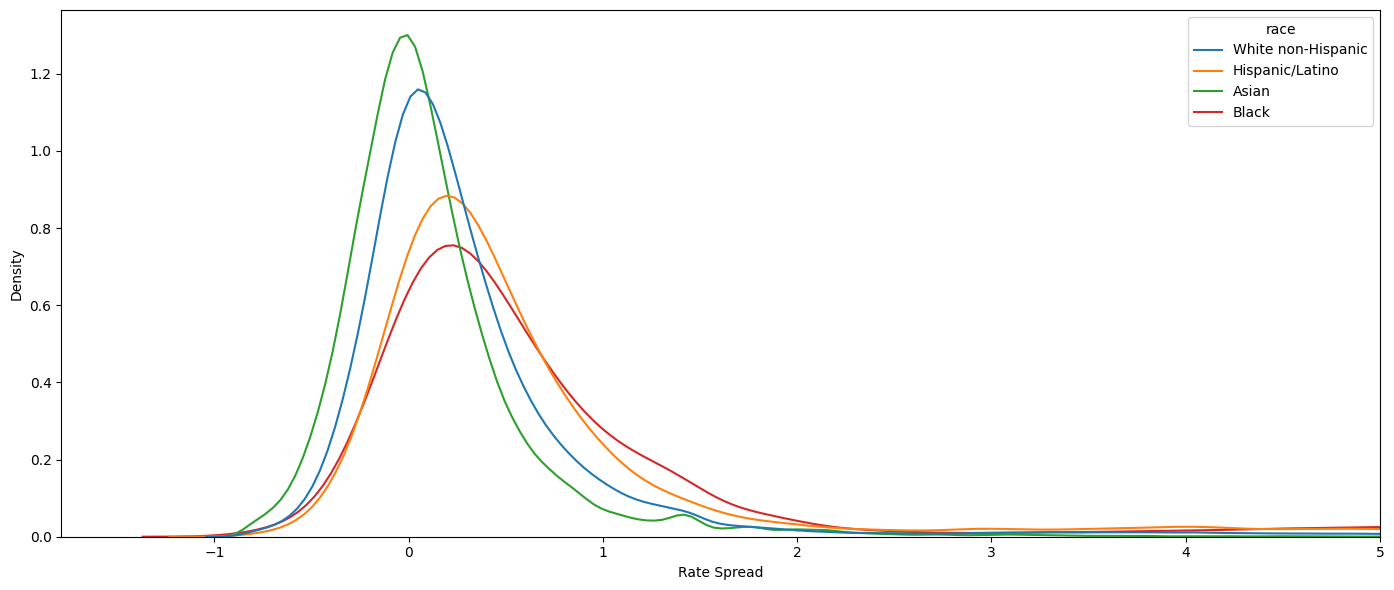

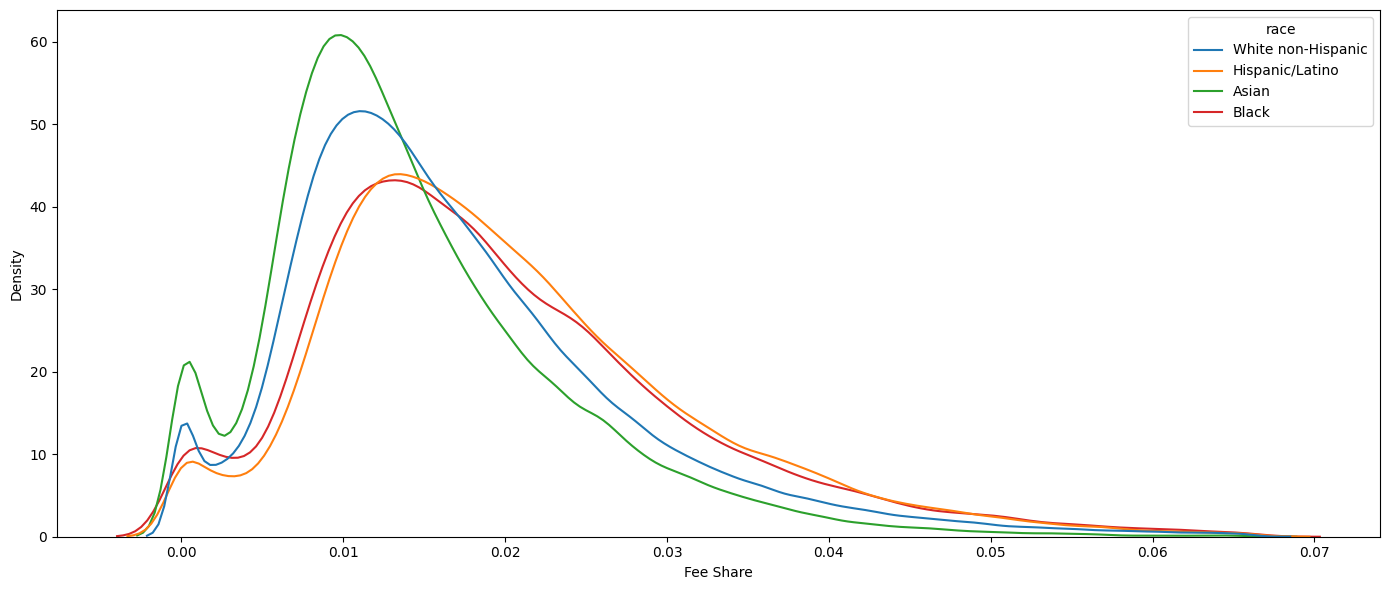

In [9]:
# KDE plot for rate spreads by race
plt.figure(figsize=(14, 6))  # Set the figure size for the plot
sns.kdeplot(data=cleaned_data, x='rate_spread', hue='race', common_norm=False)  # Create a KDE plot of rate spread, with separate density plots for each race
plt.xlabel('Rate Spread')  # Set the x-axis label
plt.ylabel('Density')  # Set the y-axis label
plt.tight_layout()  # Adjust layout to prevent overlap
plt.xlim(right=5)
plt.savefig(f"{output_plot_path}/kde_rate_spread_by_race.png", dpi=300)  # Save the plot as a PNG file in the output directory with high resolution
plt.show()  # Display the plot

# KDE plot for fee shares by race
plt.figure(figsize=(14, 6))  # Set the figure size for the plot
sns.kdeplot(data=cleaned_data, x='fee_share', hue='race', common_norm=False)  # Create a KDE plot of fee share, with separate density plots for each race
plt.xlabel('Fee Share')  # Set the x-axis label
plt.ylabel('Density')  # Set the y-axis label
plt.tight_layout()  # Adjust layout to prevent overlap
plt.savefig(f"{output_plot_path}/kde_fee_share_by_race.png", dpi=300)  # Save the plot as a PNG file in the output directory with high resolution
plt.show()  # Display the plot

## Joint distributions by race

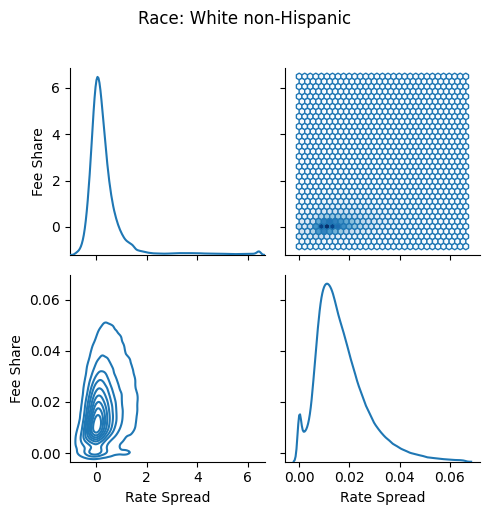

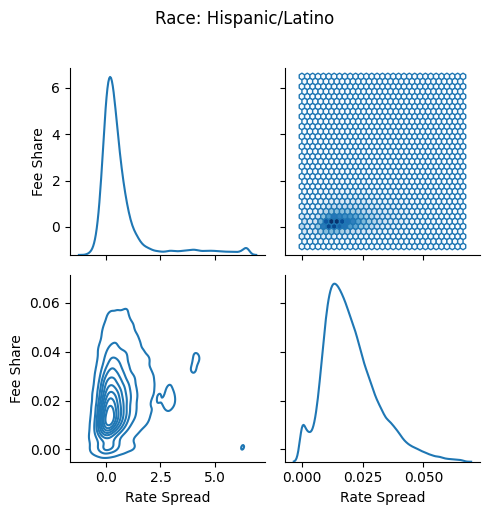

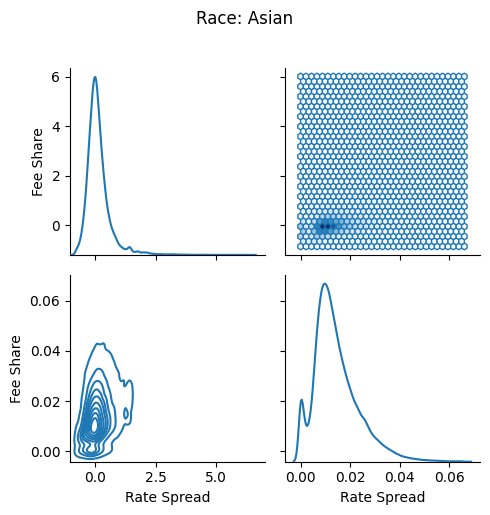

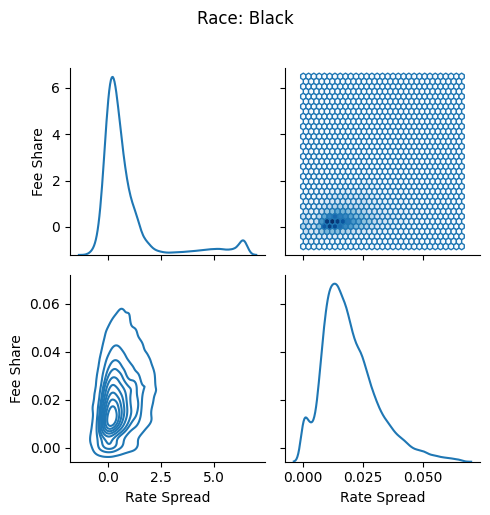

In [10]:
# Columns to plot
columns_to_plot = ['rate_spread', 'fee_share']

# Number of bins
num_bins = 30

# Define x and y labels
x_label = 'Rate Spread'
y_label = 'Fee Share'
i = 0
# Iterate over unique values of the 'race' column
for race in cleaned_data['race'].unique():
    i+=1
    # Filter data for the current race and select specific columns
    race_data = cleaned_data[cleaned_data['race'] == race][columns_to_plot]

    # Create a PairGrid for the current race using the selected columns
    g = sns.PairGrid(race_data, diag_sharey=False)

    # Plot hexbin (binned scatter) on the upper triangle
    g.map_upper(lambda x, y, **kwargs: plt.hexbin(x, y, gridsize=num_bins, cmap='Blues', **kwargs))

    # Plot KDE on the lower triangle and diagonal
    g.map_lower(sns.kdeplot)
    g.map_diag(sns.kdeplot)

    # Set axis labels
    for ax in g.axes.flatten():
        ax.set_xlabel(x_label)
        ax.set_ylabel(y_label)

    # Set title and adjust layout
    g.fig.suptitle(f"Race: {race}", y=1.02)

    # Adjust layout and show plot for each race
    plt.tight_layout()
    plt.savefig(f"{output_plot_path}/PG_Race{i}.png", dpi=300)
    plt.show()
